# **Лабораторна робота № 9**
**Тема:** Побудова надійного програмного забезпечення: Обробка виняткових ситуацій.

**Мета:** Опанувати практичні навички проектування стійких до відмов програмних комплексів мовою Python. Навчитися реалізовувати багаторівневу обробку помилок часу виконання за допомогою конструкції `try-except-else-finally`, проектувати ієрархію користувацьких класів винятків (Custom Exceptions) для конкретної інженерної предметної області, застосовувати механізм явної генерації винятків `raise` та зв'язування первинного контексту помилок через ланцюжки винятків (exception chaining). Опанувати парадигму EAFP (Easier to Ask for Forgiveness than Permission) для валідації параметрів апаратних пристроїв та конфігураційних файлів комп'ютерних систем.

**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

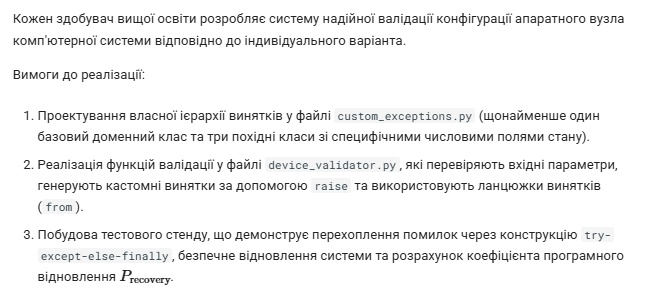

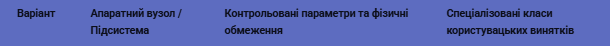
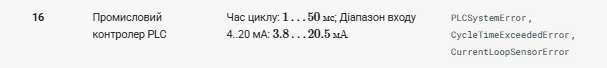

**1. Ієрархія користувацьких винятків (`custom_exceptions.py`)**

In [4]:
from pathlib import Path

lab9_dir = Path("lab09_plc_variant16").resolve()
lab9_dir.mkdir(parents=True, exist_ok=True)

custom_exceptions_code = """class PLCSystemError(Exception):
    \"\"\"Базовий виняток підсистеми керування промисловим контролером PLC.\"\"\"

    def __init__(self, message: str, error_code: int = 1000) -> None:
        self.error_code = error_code
        super().__init__(f"[PLC-ERR {error_code}] {message}")


class CycleTimeExceededError(PLCSystemError):
    \"\"\"Перевищення або порушення допустимого часу циклу PLC (1.0 .. 50.0 мс).\"\"\"

    def __init__(
        self,
        cycle_ms: float,
        min_allowed_ms: float = 1.0,
        max_allowed_ms: float = 50.0,
        error_code: int = 1101,
    ) -> None:
        self.cycle_ms = cycle_ms
        self.min_allowed_ms = min_allowed_ms
        self.max_allowed_ms = max_allowed_ms
        self.delta_ms = (
            max(0.0, cycle_ms - max_allowed_ms)
            if cycle_ms > max_allowed_ms
            else max(0.0, min_allowed_ms - cycle_ms)
        )
        super().__init__(
            f"Недопустимий час циклу PLC: {cycle_ms:.3f} мс (допустимо {min_allowed_ms:.1f}..{max_allowed_ms:.1f} мс, відхилення {self.delta_ms:.3f} мс).",
            error_code=error_code,
        )


class CurrentLoopSensorError(PLCSystemError):
    \"\"\"Помилка аналогового входу струмової петлі 4..20 мА (допустимо 3.8 .. 20.5 мА).\"\"\"

    def __init__(
        self,
        channel_id: int,
        current_ma: float,
        min_allowed_ma: float = 3.8,
        max_allowed_ma: float = 20.5,
        error_code: int = 1202,
    ) -> None:
        self.channel_id = channel_id
        self.current_ma = current_ma
        self.min_allowed_ma = min_allowed_ma
        self.max_allowed_ma = max_allowed_ma
        super().__init__(
            f"Канал AI#{channel_id}: струм {current_ma:.3f} мА поза межами {min_allowed_ma:.1f}..{max_allowed_ma:.1f} мА.",
            error_code=error_code,
        )


class WatchdogTimeoutError(PLCSystemError):
    \"\"\"Помилка сторожового таймера (Watchdog) контролера PLC.\"\"\"

    def __init__(
        self,
        elapsed_ms: float,
        timeout_ms: float = 100.0,
        error_code: int = 1303,
    ) -> None:
        self.elapsed_ms = elapsed_ms
        self.timeout_ms = timeout_ms
        self.overrun_ms = max(0.0, elapsed_ms - timeout_ms)
        super().__init__(
            f"Спрацював сторожовий таймер PLC: {elapsed_ms:.2f} мс при ліміті {timeout_ms:.2f} мс (+{self.overrun_ms:.2f} мс).",
            error_code=error_code,
        )
"""

(lab9_dir / "custom_exceptions.py").write_text(custom_exceptions_code, encoding="utf-8")
print("Створено:", lab9_dir / "custom_exceptions.py")


Створено: D:\Діма\Програмування\Python\Приклади phyton\З університета\Python база\Labs\Lab9\lab09_plc_variant16\custom_exceptions.py


**2. Модуль валідації параметрів PLC (`device_validator.py`) у парадигмі EAFP з ланцюжками винятків (`raise ... from ...`)**

In [5]:
from pathlib import Path

lab9_dir = Path("lab09_plc_variant16").resolve()

validator_code = """from custom_exceptions import (
    PLCSystemError,
    CycleTimeExceededError,
    CurrentLoopSensorError,
    WatchdogTimeoutError,
)

MIN_CYCLE_MS = 1.0
MAX_CYCLE_MS = 50.0
MIN_CURRENT_MA = 3.8
MAX_CURRENT_MA = 20.5


def validate_cycle_time(raw_cycle_ms: object) -> float:
    \"\"\"Валідує час циклу PLC у межах 1..50 мс за парадигмою EAFP.\"\"\"
    try:
        cycle_ms = float(raw_cycle_ms)
    except (TypeError, ValueError) as exc:
        raise PLCSystemError(f"Некоректний формат часу циклу '{raw_cycle_ms}'.", error_code=1100) from exc

    if cycle_ms < MIN_CYCLE_MS or cycle_ms > MAX_CYCLE_MS:
        raise CycleTimeExceededError(
            cycle_ms=cycle_ms,
            min_allowed_ms=MIN_CYCLE_MS,
            max_allowed_ms=MAX_CYCLE_MS,
        )
    return cycle_ms


def validate_current_loop_channel(channel_cfg: dict) -> tuple[int, float]:
    \"\"\"Валідує канал струмової петлі 4..20 мА (3.8..20.5 мА) за парадигмою EAFP.\"\"\"
    try:
        ch_id = int(channel_cfg["channel"])
        current_ma = float(channel_cfg["current_ma"])
    except (KeyError, TypeError, ValueError) as exc:
        raise PLCSystemError("Помилка структури або типів даних каналу струмової петлі.", error_code=1200) from exc

    if current_ma < MIN_CURRENT_MA or current_ma > MAX_CURRENT_MA:
        raise CurrentLoopSensorError(
            channel_id=ch_id,
            current_ma=current_ma,
            min_allowed_ma=MIN_CURRENT_MA,
            max_allowed_ma=MAX_CURRENT_MA,
        )
    return ch_id, current_ma


def validate_watchdog_interval(raw_elapsed_ms: object, timeout_ms: float = 100.0) -> float:
    \"\"\"Перевіряє інтервал сторожового таймера PLC.\"\"\"
    try:
        elapsed_ms = float(raw_elapsed_ms)
        limit_ms = float(timeout_ms)
    except (TypeError, ValueError) as exc:
        raise PLCSystemError("Некоректні числові параметри сторожового таймера.", error_code=1300) from exc

    if elapsed_ms > limit_ms:
        raise WatchdogTimeoutError(elapsed_ms=elapsed_ms, timeout_ms=limit_ms)
    return elapsed_ms


def validate_plc_snapshot(snapshot: dict) -> dict:
    \"\"\"Комплексна валідація стану контролера PLC.\"\"\"
    try:
        raw_cycle = snapshot["cycle_ms"]
        channels = snapshot["channels"]
        raw_watchdog = snapshot["watchdog_ms"]
    except (KeyError, TypeError) as exc:
        raise PLCSystemError("Відсутні обов'язкові поля у знімку стану PLC.", error_code=1001) from exc

    valid_cycle = validate_cycle_time(raw_cycle)

    try:
        iterator = iter(channels)
    except TypeError as exc:
        raise PLCSystemError("Поле 'channels' має бути ітерованою колекцією.", error_code=1201) from exc

    validated_channels = []
    for ch in iterator:
        validated_channels.append(validate_current_loop_channel(ch))

    valid_watchdog = validate_watchdog_interval(raw_watchdog)

    return {
        "cycle_ms": valid_cycle,
        "channels": validated_channels,
        "watchdog_ms": valid_watchdog,
    }
"""

(lab9_dir / "device_validator.py").write_text(validator_code, encoding="utf-8")
print("Створено:", lab9_dir / "device_validator.py")


Створено: D:\Діма\Програмування\Python\Приклади phyton\З університета\Python база\Labs\Lab9\lab09_plc_variant16\device_validator.py


**3. Тестовий стенд (`try-except-else-finally`), відновлення системи та розрахунок $P_{\text{recovery}}$**

In [6]:
import sys
from pathlib import Path

lab9_dir = Path("lab09_plc_variant16").resolve()
if str(lab9_dir) not in sys.path:
    sys.path.insert(0, str(lab9_dir))

from custom_exceptions import (
    PLCSystemError,
    CycleTimeExceededError,
    CurrentLoopSensorError,
    WatchdogTimeoutError,
)
from device_validator import validate_plc_snapshot

test_scenarios = [
    {
        "name": "Сценарій 1: Штатний цикл PLC (12.5 мс, 12.4 мА)",
        "data": {
            "cycle_ms": 12.5,
            "channels": [{"channel": 1, "current_ma": 12.4}, {"channel": 2, "current_ma": 4.2}],
            "watchdog_ms": 25.0,
        },
        "recoverable": True,
    },
    {
        "name": "Сценарій 2: Перевищення часу циклу (68.0 мс > 50.0 мс)",
        "data": {
            "cycle_ms": 68.0,
            "channels": [{"channel": 1, "current_ma": 15.0}],
            "watchdog_ms": 40.0,
        },
        "recoverable": True,
    },
    {
        "name": "Сценарій 3: Струм поза межами 3.8..20.5 мА (2.1 мА на AI#1)",
        "data": {
            "cycle_ms": 10.0,
            "channels": [{"channel": 1, "current_ma": 2.1}],
            "watchdog_ms": 20.0,
        },
        "recoverable": True,
    },
    {
        "name": "Сценарій 4: Некоректний тип у конфігурації ('abc' мс)",
        "data": {
            "cycle_ms": "abc",
            "channels": [{"channel": 1, "current_ma": 10.0}],
            "watchdog_ms": 15.0,
        },
        "recoverable": True,
    },
    {
        "name": "Сценарій 5: Перевантаження струмової петлі (24.8 мА на AI#3)",
        "data": {
            "cycle_ms": 15.0,
            "channels": [{"channel": 3, "current_ma": 24.8}],
            "watchdog_ms": 30.0,
        },
        "recoverable": False,
    },
    {
        "name": "Сценарій 6: Спрацювання сторожового таймера (145.0 мс > 100.0 мс)",
        "data": {
            "cycle_ms": 18.0,
            "channels": [{"channel": 1, "current_ma": 8.5}],
            "watchdog_ms": 145.0,
        },
        "recoverable": True,
    },
]

plc_safe_state = {"mode": "RUN", "safe_outputs_engaged": False}

total_runs = 0
passed_runs = 0
failed_runs = 0
recovered_runs = 0

for sc in test_scenarios:
    total_runs += 1
    print(f"\n--- {sc['name']} ---")
    try:
        validated = validate_plc_snapshot(sc["data"])
    except CycleTimeExceededError as exc:
        failed_runs += 1
        print(f"Перехоплено CycleTimeExceededError: {exc}")
        if sc["recoverable"]:
            plc_safe_state["mode"] = "DEGRADED_RECOVERY"
            recovered_runs += 1
            print("  -> Виконано перехід у безпечний цикл із корекцією таймінгу.")
    except CurrentLoopSensorError as exc:
        failed_runs += 1
        print(f"Перехоплено CurrentLoopSensorError: {exc}")
        if sc["recoverable"]:
            plc_safe_state["mode"] = "SENSOR_ISOLATION"
            recovered_runs += 1
            print(f"  -> Ізольовано канал AI#{exc.channel_id} та переключено на резервне значення.")
    except WatchdogTimeoutError as exc:
        failed_runs += 1
        print(f"Перехоплено WatchdogTimeoutError: {exc}")
        if sc["recoverable"]:
            plc_safe_state["mode"] = "WATCHDOG_RESET"
            recovered_runs += 1
            print("  -> Виконано м'який перезапуск задач контролера.")
    except PLCSystemError as exc:
        failed_runs += 1
        print(f"Перехоплено базовий PLCSystemError: {exc}")
        if exc.__cause__ is not None:
            print(f"  -> Першопричина (__cause__): {type(exc.__cause__).__name__}: {exc.__cause__}")
        if sc["recoverable"]:
            plc_safe_state["mode"] = "SAFE_HOLD"
            recovered_runs += 1
            print("  -> Застосовано резервну конфігурацію за замовчуванням.")
    else:
        passed_runs += 1
        plc_safe_state["mode"] = "RUN"
        plc_safe_state["safe_outputs_engaged"] = False
        print(f"Успішна валідація стану PLC: {validated}")
    finally:
        plc_safe_state["safe_outputs_engaged"] = True
        print(f"  [finally] Безпечний стан виходів зафіксовано: {plc_safe_state}")

p_recovery = (recovered_runs / failed_runs) if failed_runs > 0 else 1.0

print("\n" + "=" * 72)
print("ПІДСУМКИ ТЕСТОВОГО СТЕНДУ PLC")
print("=" * 72)
print(f"Усього сценаріїв виконано    : {total_runs}")
print(f"Успішних без помилок         : {passed_runs}")
print(f"Відмов / винятків (N_failed) : {failed_runs}")
print(f"Успішно відновлено (N_rec)    : {recovered_runs}")
print(f"Коефіцієнт відновлення P_recovery = {recovered_runs}/{failed_runs} = {p_recovery:.4f}")
print("=" * 72)



--- Сценарій 1: Штатний цикл PLC (12.5 мс, 12.4 мА) ---
Успішна валідація стану PLC: {'cycle_ms': 12.5, 'channels': [(1, 12.4), (2, 4.2)], 'watchdog_ms': 25.0}
  [finally] Безпечний стан виходів зафіксовано: {'mode': 'RUN', 'safe_outputs_engaged': True}

--- Сценарій 2: Перевищення часу циклу (68.0 мс > 50.0 мс) ---
Перехоплено CycleTimeExceededError: [PLC-ERR 1101] Недопустимий час циклу PLC: 68.000 мс (допустимо 1.0..50.0 мс, відхилення 18.000 мс).
  -> Виконано перехід у безпечний цикл із корекцією таймінгу.
  [finally] Безпечний стан виходів зафіксовано: {'mode': 'DEGRADED_RECOVERY', 'safe_outputs_engaged': True}

--- Сценарій 3: Струм поза межами 3.8..20.5 мА (2.1 мА на AI#1) ---
Перехоплено CurrentLoopSensorError: [PLC-ERR 1202] Канал AI#1: струм 2.100 мА поза межами 3.8..20.5 мА.
  -> Ізольовано канал AI#1 та переключено на резервне значення.
  [finally] Безпечний стан виходів зафіксовано: {'mode': 'SENSOR_ISOLATION', 'safe_outputs_engaged': True}

--- Сценарій 4: Некоректний т

### **Висновки**

1. **Надійність та кастомні винятки:** Ієрархія доменних винятків (`PLCSystemError` та похідні `CycleTimeExceededError`, `CurrentLoopSensorError`, `WatchdogTimeoutError`) зі специфічними числовими полями стану забезпечує чітку діагностику і дозволяє точно локалізувати причину збою краще, ніж повернення знеособлених числових кодів помилок.
2. **Ланцюжки винятків та `try-except-else-finally`:** Конструкція `raise ... from ...` зберігає першопричину помилки в `__cause__`, а розподіл логіки між `try`, `except`, `else` та `finally` гарантує коректне відділення штатного виконання від обробки помилок та безумовне фіксування безпечного стану пристрою.
3. **Ефективність EAFP:** Підхід EAFP спрощує валідацію вхідних значень та конфігурацій PLC без зайвих попередніх перевірок стану й зменшує ризик неузгодженості між моментом перевірки та моментом фактичного використання даних.

### **Контрольні запитання**

1. **У чому полягає принципова різниця між системними винятками, похідними від BaseException (наприклад, KeyboardInterrupt, SystemExit), та прикладними винятками, похідними від Exception?**
Винятки на кшталт `KeyboardInterrupt`, `SystemExit` та `GeneratorExit` успадковуються безпосередньо від `BaseException` (а не від `Exception`) і позначають події життєвого циклу програми/переривання виконання, які зазвичай не слід «ковтати» загальними обробниками прикладних помилок (`except Exception:`). Прикладні та стандартні програмні помилки успадковуються від `Exception` і призначені для штатної обробки в бізнес-логіці.

2. **Опишіть внутрішній механізм розкручування стека викликів (stack unwinding) у CPython. Що відбувається з об'єктами локального стекового кадру PyFrameObject при виникненні винятку?**
Коли виняток не перехоплено в поточному фреймі, CPython завершує виконання поточного кадру, передає виняток у викликаючий фрейм і просувається вгору по стеку викликів, поки не знайде відповідний обробник `except` або не досягне верхнього рівня програми. Під час розкручування локальні посилання кадру звільняються (лічильники посилань об'єктів зменшуються, викликаються деструктори/фіналізатори при досягненні нуля), а об'єкт traceback фіксує послідовність пройдених кадрів.

3. **Поясніть призначення та синтаксис ланцюжків винятків (exception chaining, PEP 3134) за допомогою конструкції raise ... from .... Яка інформація зберігається в атрибуті __cause__?**
Синтаксис `raise NewError(...) from original_exc` дозволяє явно пов'язати новий виняток із першопричиною, яка призвела до збою. Посилання на `original_exc` зберігається в атрибуті `__cause__` нового винятку (а прапорець `__suppress_context__` встановлюється в `True`), що дає змогу простежити і низькорівневу причину, і високорівневий доменний контекст.

4. **Порівняйте парадигми програмування EAFP (Easier to Ask for Forgiveness than Permission) та LBYL (Look Before You Leap). Чому в багатопотокових системах підхід EAFP є більш стійким до стану гонитви TOCTOU?**
LBYL спочатку перевіряє умову/наявність/допустимість, а потім виконує дію; EAFP одразу виконує дію в `try` і перехоплює виняток при помилці. У багатопотоковому середовищі між перевіркою та дією в LBYL стан ресурсу може встигнути змінитися іншим потоком (стан гонитви TOCTOU — Time-of-Check to Time-of-Use), тоді як EAFP працює безпосередньо з фактом виконання операції та атомарніше реагує на реальний стан ресурсу.

5. **Чому блоки except повинні розташовуватися строго у порядку від найбільш спеціалізованих (похідних) класів до найбільш загальних (базових)? Що станеться, якщо першим блоком вказати except Exception:?**
CPython перевіряє блоки `except` зверху вниз і обирає перший, з яким виняток сумісний за `isinstance`. Якщо першим поставити `except Exception:`, він перехопить усі похідні винятки (включно з `CycleTimeExceededError` чи `CurrentLoopSensorError`), і більш спеціалізовані блоки нижче ніколи не виконаються.

6. **За яких умов виконується блок else у конструкції try-except-else-finally? Чому відокремлення коду успішного виконання в блок else є кращою практикою, ніж розміщення його в кінці блоку try?**
Блок `else` виконується лише тоді, коли код у блоці `try` завершився без генерації винятків (і не було `return`/`break`/`continue` у `try`). Винесення продовження штатної логіки в `else` гарантує, що обробники `except` не перехоплять випадкові помилки з коду, який уже не стосується саме тієї ризикованої операції, що перевірялася в `try`.